In [ ]:
import datetime
import pandas as pd
import numpy as np
import yfinance as yf
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
indices_symbols = {
    'australia': ['^AXJO', '^AORD'],
    'new zealand': ['^NZ50'],
    'india': ['^BSESN', '^NSEI', '^CNX100'],
    'pakistan': ['^KSE'],
    'singapore': ['MSCI'],
    'japan': ['^N225', '^NJAQ.OS', 'JPXN'],
    'china': ['000001.SS'],
    'hong kong': ['^HSI'],
    'indonesia': ['^JKSE'],
    'malaysia': ['^KLSE'],
    'philippines': ['PSEI.PS'],
    'south korea': ['^KS11', '^KQ11'],
    'taiwan': ['^TWII', 'PEX'],
    'thailand': ['^SET.BK'],
    'austria': ['^ATX'],
    'belgium': ['^BFX'],
    'denmark': ['^OMXC20'],
    'finland': ['^OMXH25'],
    'france': ['^FCHI'],
    'germany': ['^GDAXI', '^STOXX50E'],
    'greece': ['GD.AT'],
    'hungary': ['^BUX'],
    'iceland': ['ICE'],
    'ireland': ['^ISEQ'],
    'italy': ['FTSEMIB.MI'],
    'netherlands': ['^AEX'],
    'poland': ['^WIG20'],
    'russia': ['IMOEX.ME'],
    'spain': ['^IBEX'],
    'sweden': ['^OMX'],
    'switzerland': ['^SSMI'],
    'turkey': ['XU100.IS'],
    'united kingdom': ['^FTSE', '^FTMC'],
    'argentina': ['^MERV'],
    'brazil': ['^BVSP', '^IBX50'],
    'chile': ['^IPSA'],
    'colombia': ['ICOLCAP.CL'],
    'mexico': ['^MXX'],
    'peru': ['^SPBLPGPT'],
    'united states': ['^DJI', '^NDX', '^GSPC', '^NYA', '^RUT', '^DJA'],
    'canada': ['^GSPTSE'],
    'israel': ['TA35.TA'],
    'qatar': ['QAT'],
    'dubai': ['DFM.AE'],
    'ukraine': ['UTX.VI']
}
cnt = 0
print(len(indices_symbols))
for country in indices_symbols:
  cnt+=len(indices_symbols[country])
  print(country, len( indices_symbols[country]), indices_symbols[country])

print(cnt)

45
australia 2 ['^AXJO', '^AORD']
new zealand 1 ['^NZ50']
india 3 ['^BSESN', '^NSEI', '^CNX100']
pakistan 1 ['^KSE']
singapore 1 ['MSCI']
japan 3 ['^N225', '^NJAQ.OS', 'JPXN']
china 1 ['000001.SS']
hong kong 1 ['^HSI']
indonesia 1 ['^JKSE']
malaysia 1 ['^KLSE']
philippines 1 ['PSEI.PS']
south korea 2 ['^KS11', '^KQ11']
taiwan 2 ['^TWII', 'PEX']
thailand 1 ['^SET.BK']
austria 1 ['^ATX']
belgium 1 ['^BFX']
denmark 1 ['^OMXC20']
finland 1 ['^OMXH25']
france 1 ['^FCHI']
germany 2 ['^GDAXI', '^STOXX50E']
greece 1 ['GD.AT']
hungary 1 ['^BUX']
iceland 1 ['ICE']
ireland 1 ['^ISEQ']
italy 1 ['FTSEMIB.MI']
netherlands 1 ['^AEX']
poland 1 ['^WIG20']
russia 1 ['IMOEX.ME']
spain 1 ['^IBEX']
sweden 1 ['^OMX']
switzerland 1 ['^SSMI']
turkey 1 ['XU100.IS']
united kingdom 2 ['^FTSE', '^FTMC']
argentina 1 ['^MERV']
brazil 2 ['^BVSP', '^IBX50']
chile 1 ['^IPSA']
colombia 1 ['ICOLCAP.CL']
mexico 1 ['^MXX']
peru 1 ['^SPBLPGPT']
united states 6 ['^DJI', '^NDX', '^GSPC', '^NYA', '^RUT', '^DJA']
canada 1 ['^G

In [ ]:
data = pd.DataFrame()
start_date = '2018-01-01'
end_date = '2025-01-02'

for country in indices_symbols:
  for symbol in indices_symbols[country]:
    print(symbol)
    index_data = yf.download(symbol, start=start_date, end=end_date)
    close_data = index_data['Close']
    data[symbol] = close_data

^AXJO
YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


^AORD


[*********************100%***********************]  1 of 1 completed


^NZ50


[*********************100%***********************]  1 of 1 completed


... (105 outputs left out)

DFM.AE


[*********************100%***********************]  1 of 1 completed


UTX.VI


[*********************100%***********************]  1 of 1 completed


In [ ]:
print(data.shape)
data.head()

(1771, 60)


,^AXJO,^AORD,^NZ50,^BSESN,^NSEI,^CNX100,^KSE,MSCI,^N225,^NJAQ.OS,...,^NDX,^GSPC,^NYA,^RUT,^DJA,^GSPTSE,TA35.TA,QAT,DFM.AE,UTX.VI
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,6061.299805,6166.000000,NaN,33812.261719,10442.200195,10899.299805,41486.871094,118.559677,NaN,NaN,...,6511.339844,2695.810059,12902.719727,1550.010010,8360.910156,16310.000000,1532.119995,12.328716,0.953832,88.077972
2018-01-03,6070.399902,6175.299805,8424.910156,33793.378906,10443.200195,10910.049805,41544.269531,120.361084,NaN,NaN,...,6575.799805,2713.060059,12957.280273,1552.579956,8366.870117,16371.599609,1525.770020,12.351367,0.962273,88.077972
2018-01-04,6077.100098,6185.399902,8443.500000,33969.640625,10504.799805,10982.150391,41908.710938,122.255386,23506.330078,4000.629883,...,6584.580078,2723.989990,13028.459961,1555.719971,8393.620117,16412.900391,1535.890015,12.358916,0.970714,89.396248
2018-01-05,6122.299805,6229.700195,8455.549805,34153.851562,10558.849609,11051.250000,42523.988281,123.527557,23714.529297,4027.580078,...,6653.290039,2743.149902,13103.230469,1560.010010,8449.129883,16349.400391,NaN,12.340798,NaN,89.808220
2018-01-08,6130.399902,6236.500000,8425.480469,34352.789062,10623.599609,11120.549805,43112.121094,123.694687,NaN,NaN,...,6676.629883,2747.709961,13114.349609,1561.810059,8477.389648,16317.700195,1530.209961,12.698654,0.970714,92.280014


In [ ]:
data2 = data.ffill()
data2 = data.bfill()

In [ ]:
print(data2.shape)
data2.head()

(1771, 60)


,^AXJO,^AORD,^NZ50,^BSESN,^NSEI,^CNX100,^KSE,MSCI,^N225,^NJAQ.OS,...,^NDX,^GSPC,^NYA,^RUT,^DJA,^GSPTSE,TA35.TA,QAT,DFM.AE,UTX.VI
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,6061.299805,6166.000000,8424.910156,33812.261719,10442.200195,10899.299805,41486.871094,118.559677,23506.330078,4000.629883,...,6511.339844,2695.810059,12902.719727,1550.010010,8360.910156,16310.000000,1532.119995,12.328716,0.953832,88.077972
2018-01-03,6070.399902,6175.299805,8424.910156,33793.378906,10443.200195,10910.049805,41544.269531,120.361084,23506.330078,4000.629883,...,6575.799805,2713.060059,12957.280273,1552.579956,8366.870117,16371.599609,1525.770020,12.351367,0.962273,88.077972
2018-01-04,6077.100098,6185.399902,8443.500000,33969.640625,10504.799805,10982.150391,41908.710938,122.255386,23506.330078,4000.629883,...,6584.580078,2723.989990,13028.459961,1555.719971,8393.620117,16412.900391,1535.890015,12.358916,0.970714,89.396248
2018-01-05,6122.299805,6229.700195,8455.549805,34153.851562,10558.849609,11051.250000,42523.988281,123.527557,23714.529297,4027.580078,...,6653.290039,2743.149902,13103.230469,1560.010010,8449.129883,16349.400391,1530.209961,12.340798,0.970714,89.808220
2018-01-08,6130.399902,6236.500000,8425.480469,34352.789062,10623.599609,11120.549805,43112.121094,123.694687,23849.990234,4075.659912,...,6676.629883,2747.709961,13114.349609,1561.810059,8477.389648,16317.700195,1530.209961,12.698654,0.970714,92.280014


In [ ]:
tickers = list(data2.columns)
len(tickers)
print((tickers))
tickers_dict = {}
for i in range(len(tickers)):
  tickers_dict[i] = tickers[i]
print((tickers_dict))
data3 = pd.DataFrame(columns = tickers)

for ticker in tickers:
  data3[ticker] = np.log(data2[ticker]) - np.log(data2[ticker].shift(1))

data3

['^AXJO', '^AORD', '^NZ50', '^BSESN', '^NSEI', '^CNX100', '^KSE', 'MSCI', '^N225', '^NJAQ.OS', 'JPXN', '000001.SS', '^HSI', '^JKSE', '^KLSE', 'PSEI.PS', '^KS11', '^KQ11', '^TWII', 'PEX', '^SET.BK', '^ATX', '^BFX', '^OMXC20', '^OMXH25', '^FCHI', '^GDAXI', '^STOXX50E', 'GD.AT', '^BUX', 'ICE', '^ISEQ', 'FTSEMIB.MI', '^AEX', '^WIG20', 'IMOEX.ME', '^IBEX', '^OMX', '^SSMI', 'XU100.IS', '^FTSE', '^FTMC', '^MERV', '^BVSP', '^IBX50', '^IPSA', 'ICOLCAP.CL', '^MXX', '^SPBLPGPT', '^DJI', '^NDX', '^GSPC', '^NYA', '^RUT', '^DJA', '^GSPTSE', 'TA35.TA', 'QAT', 'DFM.AE', 'UTX.VI']
{0: '^AXJO', 1: '^AORD', 2: '^NZ50', 3: '^BSESN', 4: '^NSEI', 5: '^CNX100', 6: '^KSE', 7: 'MSCI', 8: '^N225', 9: '^NJAQ.OS', 10: 'JPXN', 11: '000001.SS', 12: '^HSI', 13: '^JKSE', 14: '^KLSE', 15: 'PSEI.PS', 16: '^KS11', 17: '^KQ11', 18: '^TWII', 19: 'PEX', 20: '^SET.BK', 21: '^ATX', 22: '^BFX', 23: '^OMXC20', 24: '^OMXH25', 25: '^FCHI', 26: '^GDAXI', 27: '^STOXX50E', 28: 'GD.AT', 29: '^BUX', 30: 'ICE', 31: '^ISEQ', 32: 'FTSEM

,^AXJO,^AORD,^NZ50,^BSESN,^NSEI,^CNX100,^KSE,MSCI,^N225,^NJAQ.OS,...,^NDX,^GSPC,^NYA,^RUT,^DJA,^GSPTSE,TA35.TA,QAT,DFM.AE,UTX.VI
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-03,0.001500,0.001507,0.000000,-0.000559,0.000096,0.000986,0.001383,0.015080,0.000000,0.000000,...,0.009851,0.006378,0.004220,0.001657,0.000713,0.003770,-0.004153,0.001836,0.008811,0.000000
2018-01-04,0.001103,0.001634,0.002204,0.005202,0.005881,0.006587,0.008734,0.015616,0.000000,0.000000,...,0.001334,0.004021,0.005478,0.002020,0.003192,0.002520,0.006611,0.000611,0.008734,0.014856
2018-01-05,0.007410,0.007137,0.001426,0.005408,0.005132,0.006272,0.014575,0.010352,0.008818,0.006714,...,0.010381,0.007009,0.005723,0.002754,0.006592,-0.003876,-0.003705,-0.001467,0.000000,0.004598
2018-01-08,0.001322,0.001091,-0.003563,0.005808,0.006114,0.006251,0.013736,0.001352,0.005696,0.011867,...,0.003502,0.001661,0.000848,0.001153,0.003339,-0.001941,0.000000,0.028585,0.000000,0.027151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-23,0.016548,0.016220,0.006208,0.006368,0.007011,0.006153,NaN,0.001025,0.011801,NaN,...,0.010003,0.007261,0.004575,-0.002201,0.001890,0.006059,0.000000,0.009510,0.000000,-0.000718
2024-12-24,0.002351,0.002222,0.006928,-0.000857,-0.001087,-0.001108,NaN,0.004104,-0.003184,NaN,...,0.013602,0.010982,0.006972,0.009966,0.008306,0.003944,0.006082,0.000000,-0.006780,0.006084
2024-12-27,0.004963,0.005720,0.009921,0.002878,0.003607,0.002418,NaN,0.002760,0.031378,NaN,...,-0.015005,-0.011523,-0.005340,-0.006776,-0.005791,-0.002031,-0.015493,-0.012325,0.033448,0.000000


In [ ]:
countries_dict={}
ind=0;

for country in indices_symbols:
  for i in range(len(indices_symbols[country])):
    countries_dict[ind]=country
    ind=ind+1

countries_dict

{0: 'australia',
 1: 'australia',
 2: 'new zealand',
 3: 'india',
 4: 'india',
 5: 'india',
 6: 'pakistan',
 7: 'singapore',
 8: 'japan',
 9: 'japan',
 10: 'japan',
 11: 'china',
 12: 'hong kong',
 13: 'indonesia',
 14: 'malaysia',
 15: 'philippines',
 16: 'south korea',
 17: 'south korea',
 18: 'taiwan',
 19: 'taiwan',
 20: 'thailand',
 21: 'austria',
 22: 'belgium',
 23: 'denmark',
 24: 'finland',
 25: 'france',
 26: 'germany',
 27: 'germany',
 28: 'greece',
 29: 'hungary',
 30: 'iceland',
 31: 'ireland',
 32: 'italy',
 33: 'netherlands',
 34: 'poland',
 35: 'russia',
 36: 'spain',
 37: 'sweden',
 38: 'switzerland',
 39: 'turkey',
 40: 'united kingdom',
 41: 'united kingdom',
 42: 'argentina',
 43: 'brazil',
 44: 'brazil',
 45: 'chile',
 46: 'colombia',
 47: 'mexico',
 48: 'peru',
 49: 'united states',
 50: 'united states',
 51: 'united states',
 52: 'united states',
 53: 'united states',
 54: 'united states',
 55: 'canada',
 56: 'israel',
 57: 'qatar',
 58: 'dubai',
 59: 'ukraine'}

In [ ]:
s_dates = []
e_dates = []

start = datetime.datetime(2018, 1, 1)
end = datetime.datetime(2018, 7, 1)

while start<=datetime.datetime(2024, 12, 22):
  s_dates.append(start)
  e_dates.append(end)
  start = start + datetime.timedelta(days=14)
  end = end + datetime.timedelta(days=14)

print(start)
len(s_dates)

2024-12-23 00:00:00


182

In [ ]:
periods = len(s_dates)
mst_weight = []
for i in range(periods):
  mask = (data3.index >= s_dates[i]) & (data3.index < e_dates[i])
  period_data = data3.loc[mask]

  corr_period = period_data.corr()
  corr_period_matrix = corr_period
  corr_period_matrix = corr_period_matrix.to_numpy()
  adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

  G = nx.from_numpy_array(adjacency_matrix)
  T = nx.minimum_spanning_tree(G, ignore_nan=True)
  edges = list(T.edges.data("weight"))
  sum = 0
  for edge in edges:
    sum = sum + edge[2]
  mst_weight.append(sum)

mst_weight

[43.06766209874898,
 43.067046857243746,
 43.07104592071458,
 46.179106606842154,
 46.155975333543736,
 46.03690316293496,
 47.16446902614876,
 48.45678370600495,
 46.146712284672404,
 45.28968440068283,
 45.06932411572783,
 44.491973876989725,
 42.98221211671436,
 42.591351256728295,
 42.421583421921255,
 42.03981909852807,
 41.89844062407249,
 42.092431016379095,
 42.126435219884755,
 41.738981956127965,
 41.37910597523442,
 42.27137856287905,
 43.30104093614721,
 42.42389525411388,
 42.585880252579436,
 44.31303236309826,
 45.29826922980216,
 45.52662888051049,
 46.010887879043736,
 44.882166646717366,
 43.771480904907804,
 43.37619798198134,
 43.90466815293246,
 43.477439374572526,
 42.70270325385073,
 42.11912212630778,
 43.31476725742178,
 41.79621588001576,
 41.77096503233515,
 42.09385689190872,
 41.90863963464411,
 41.68963388911842,
 41.74790873467254,
 43.22466948771837,
 36.82119093783656,
 28.869004404315575,
 29.267441266143823,
 29.678931971439926,
 29.82878331988879,
 3

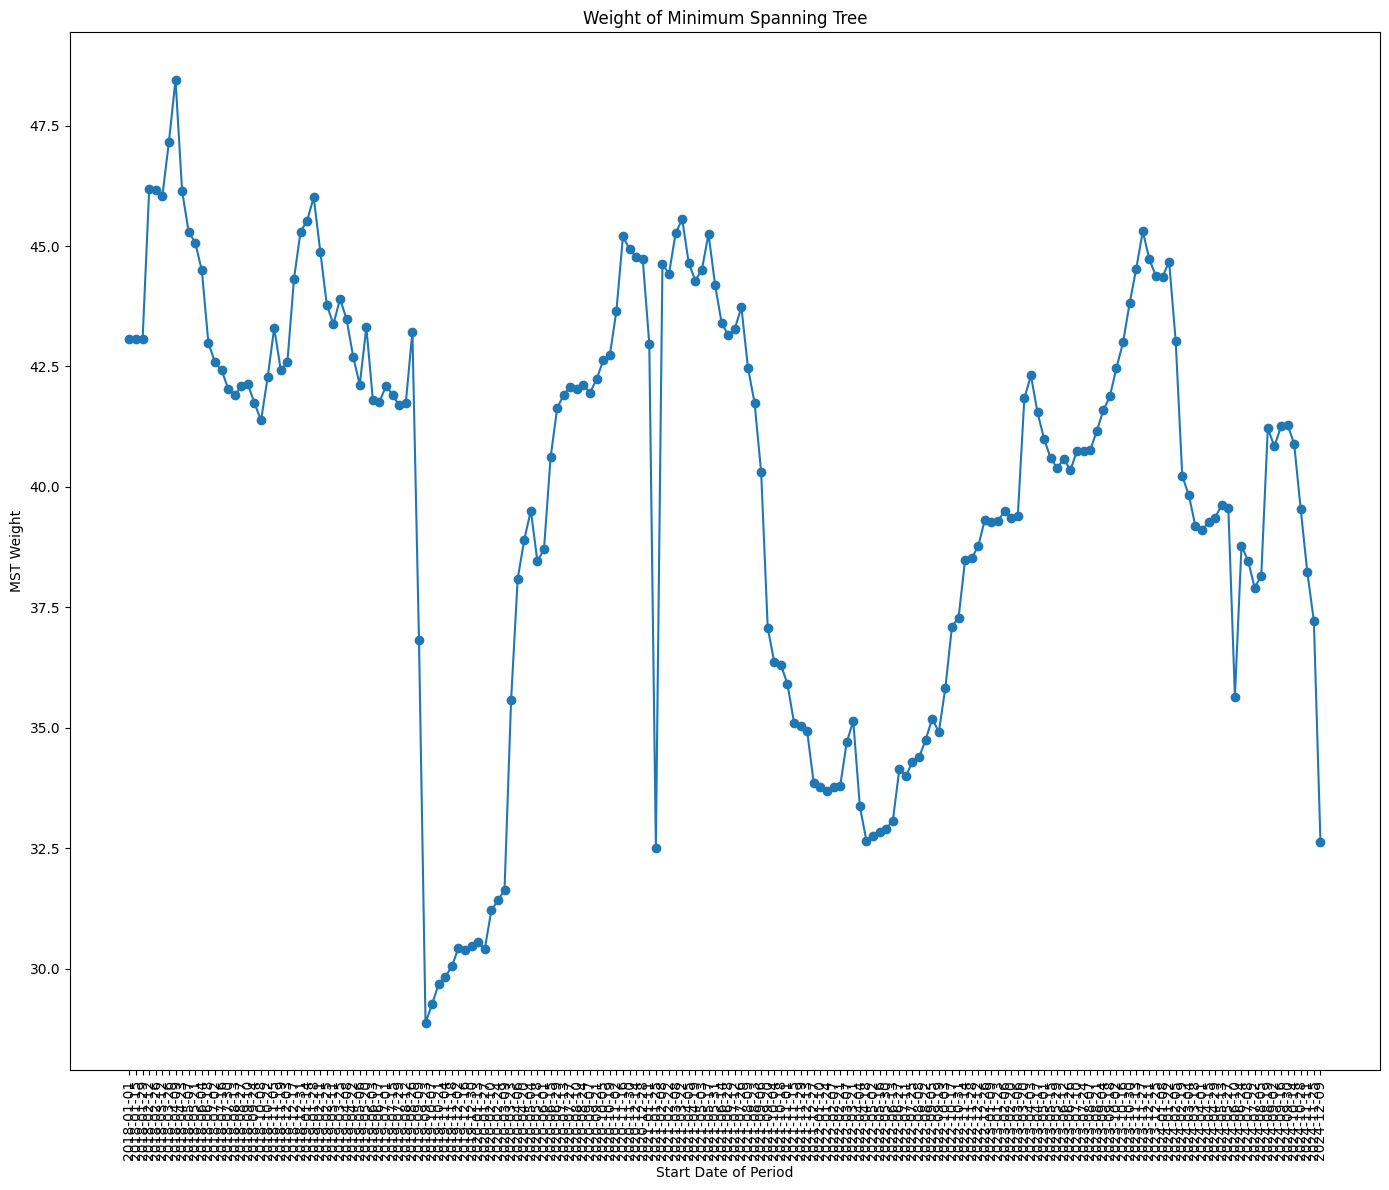

In [ ]:
x_axis = [date.strftime('%Y-%m-%d') for date in s_dates]

f = plt.figure()
f.set_figwidth(14)
f.set_figheight(12)

plt.plot(x_axis, mst_weight, marker='o')
plt.xlabel("Start Date of Period")
plt.ylabel("MST Weight")
plt.title("Weight of Minimum Spanning Tree")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

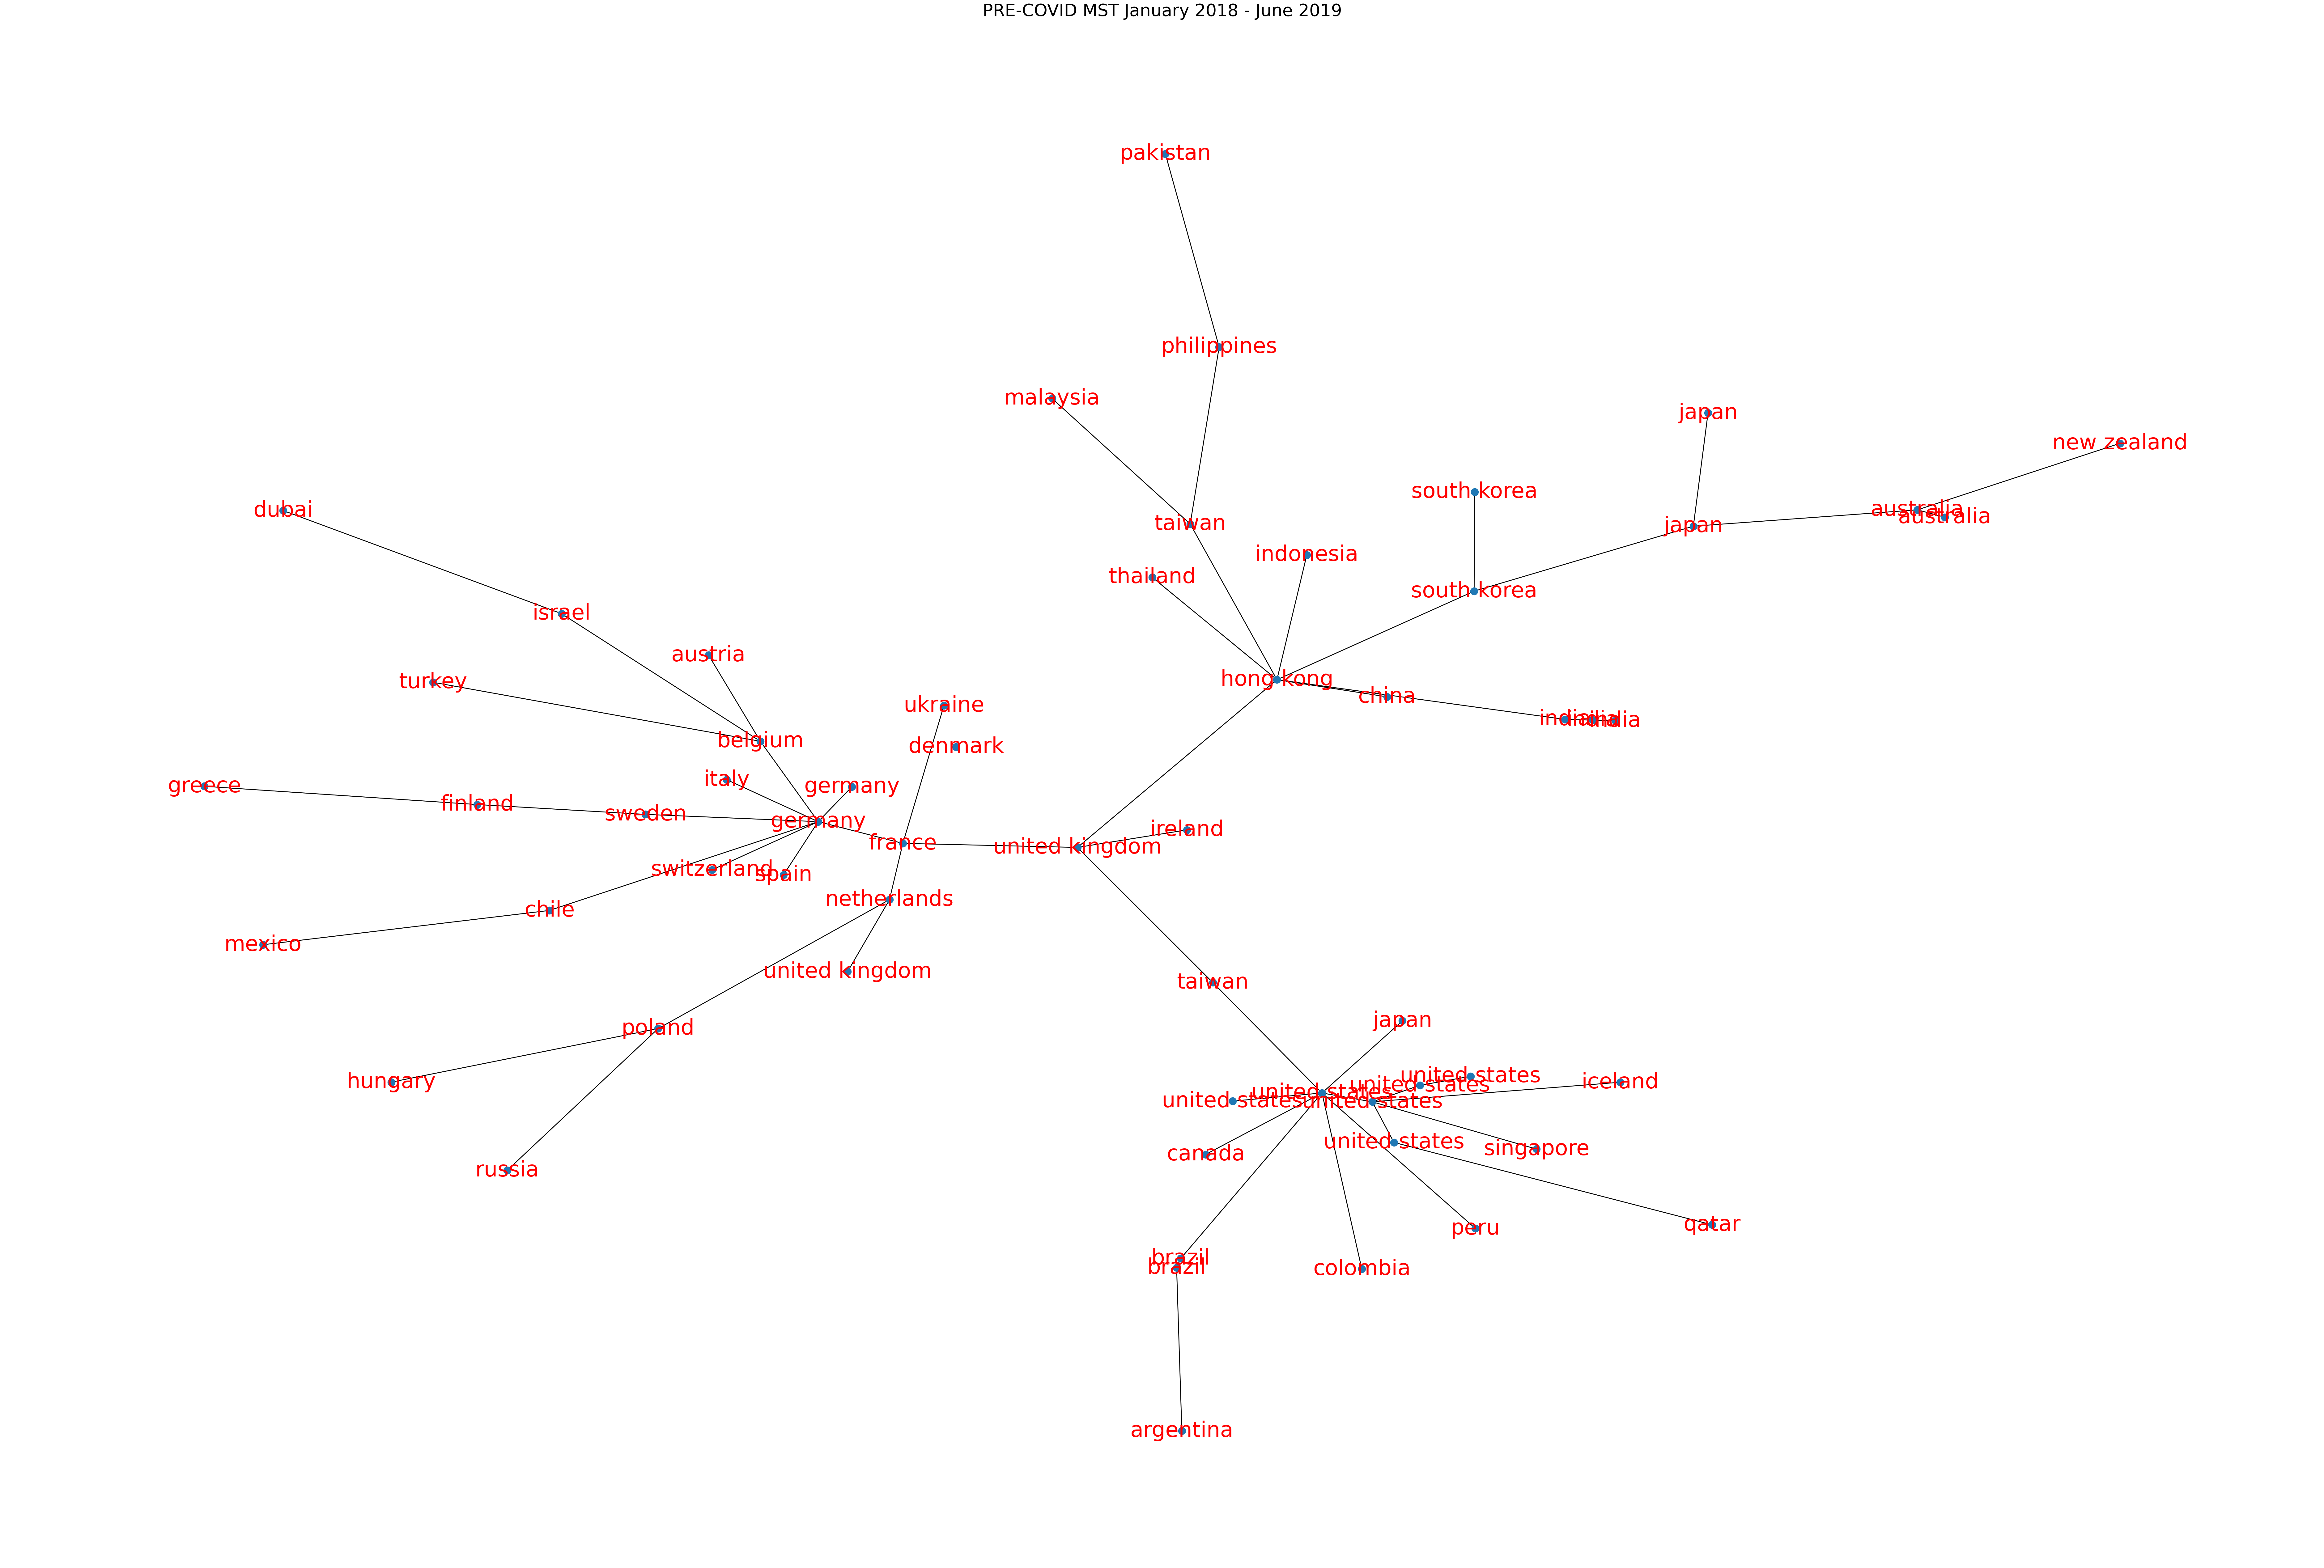

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2018, 1, 1)
end_date = datetime.datetime(2019, 7, 1)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('PRE-COVID MST January 2018 - June 2019', fontsize=40)
plt.show()

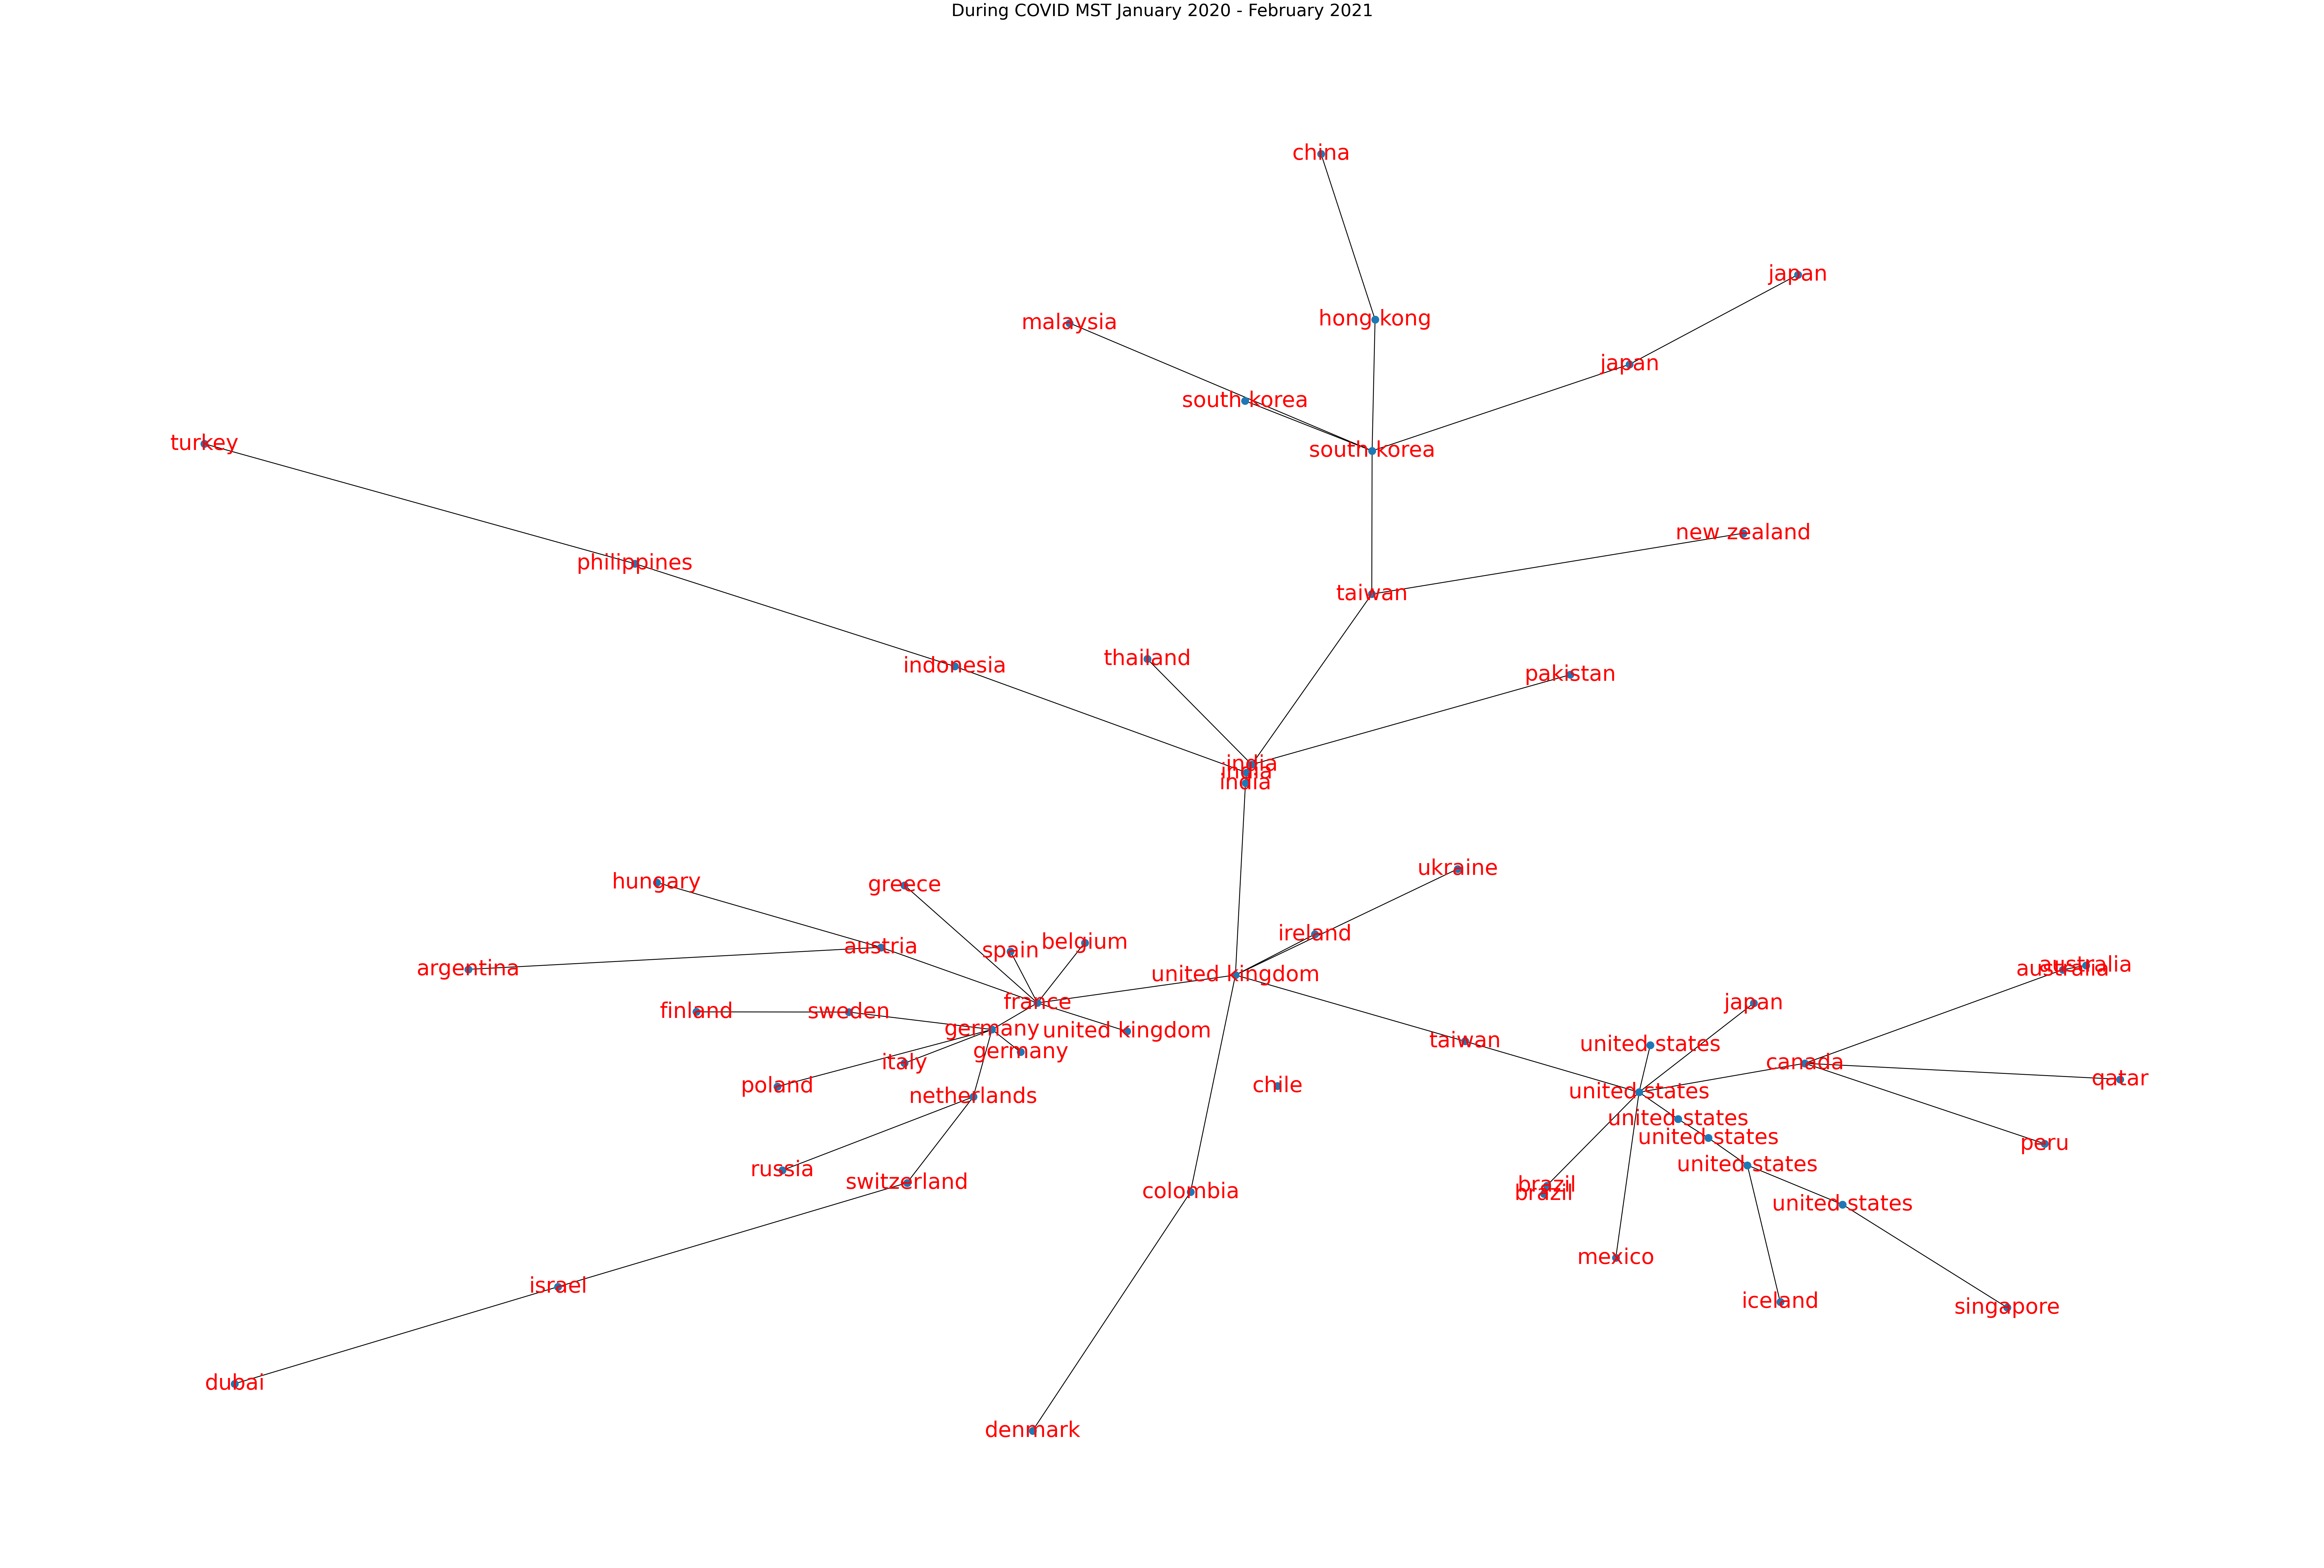

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2020, 1, 1)
end_date = datetime.datetime(2021, 3, 1)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('During COVID MST January 2020 - February 2021', fontsize=40)
plt.show()

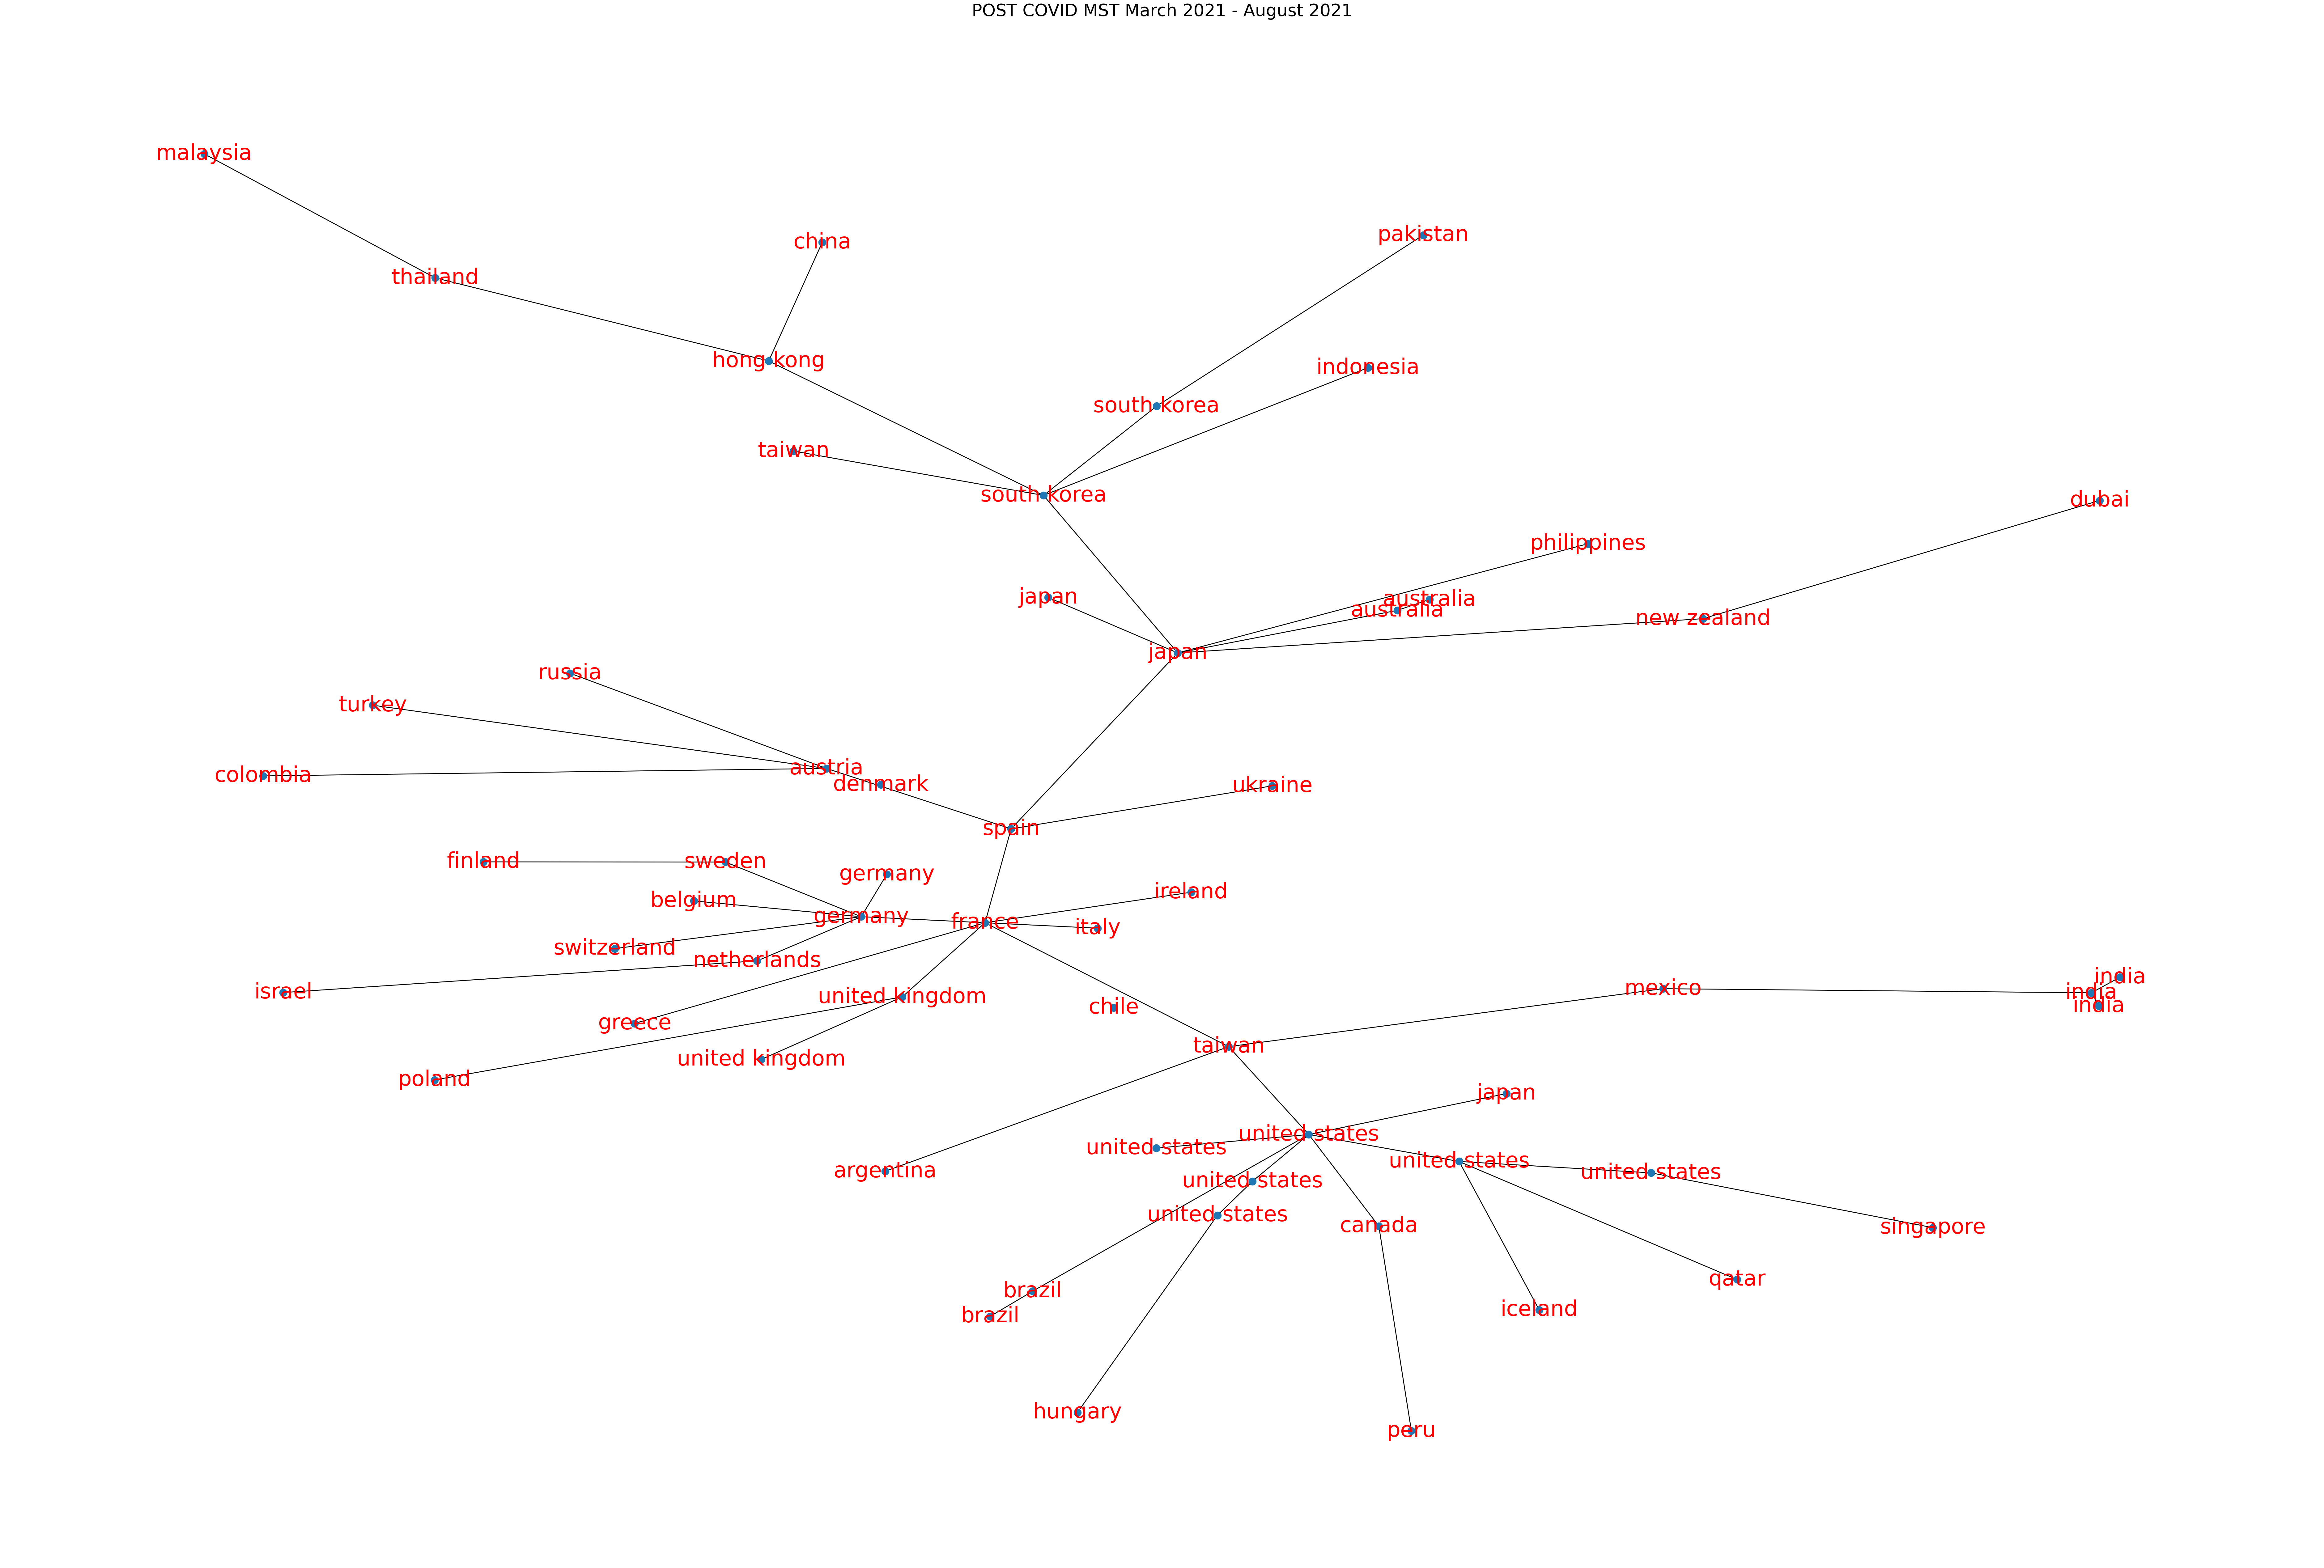

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2021, 3, 1)
end_date = datetime.datetime(2021, 8, 1)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('POST COVID MST March 2021 - August 2021', fontsize=40)
plt.show()

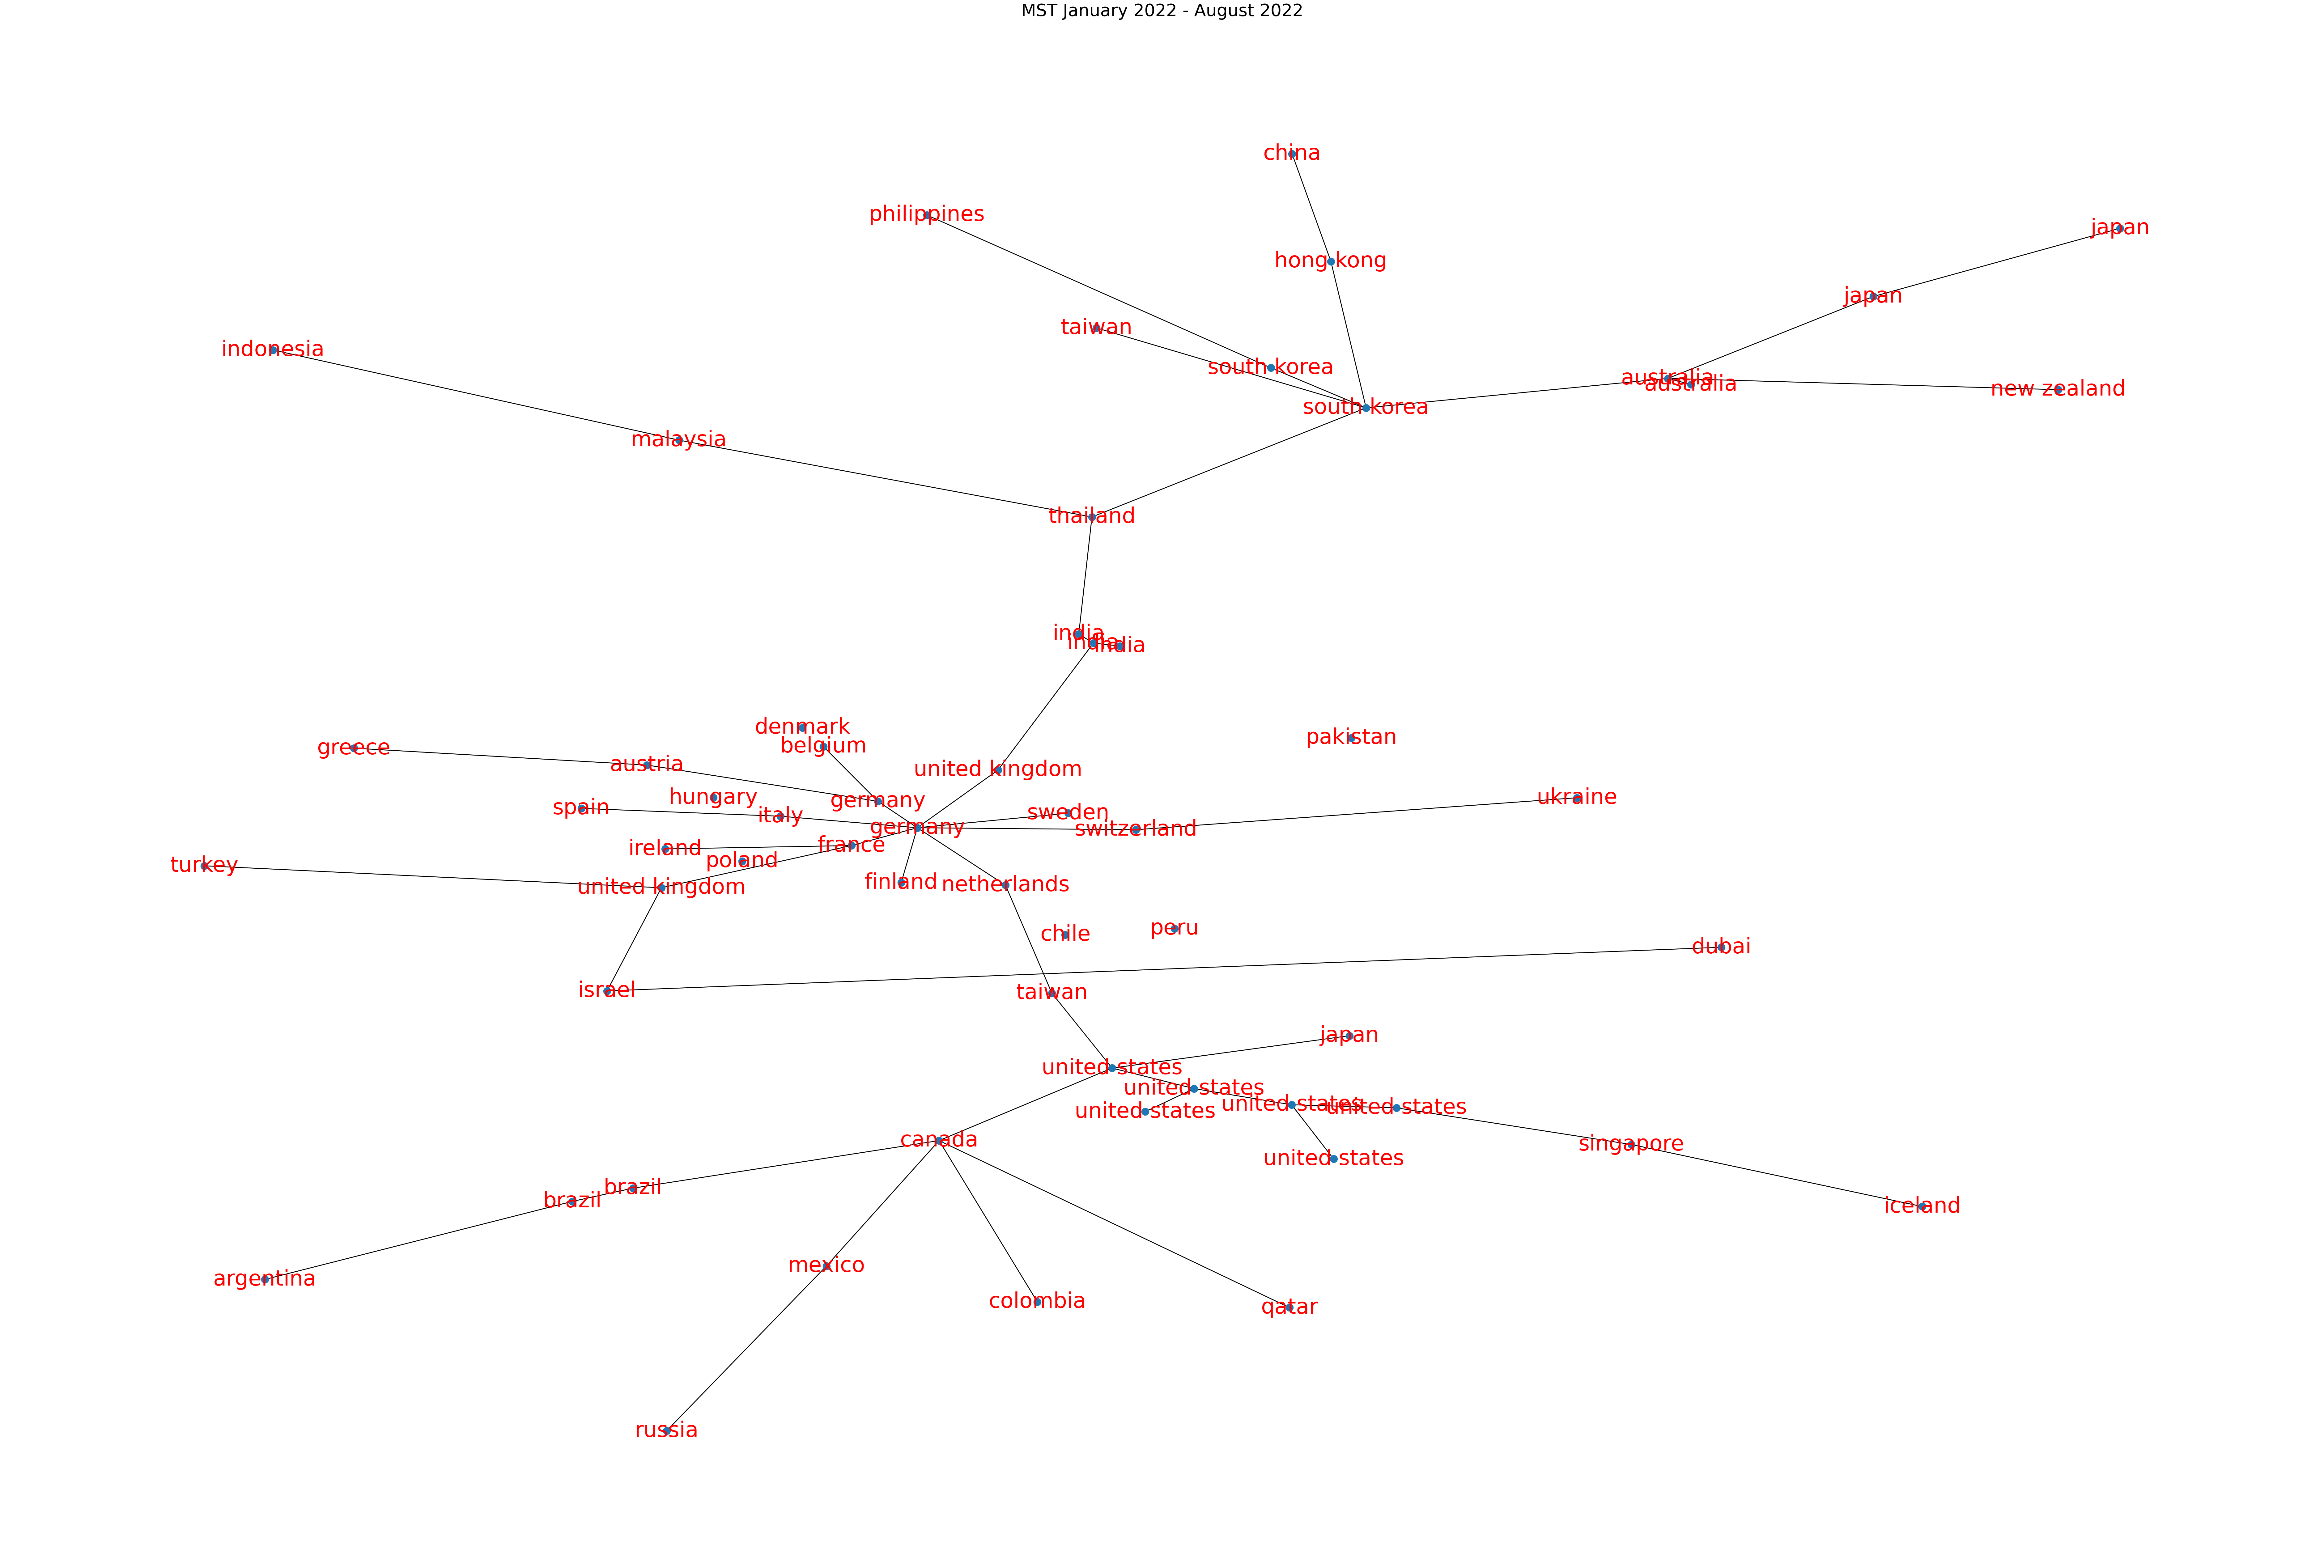

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2022, 1, 1)
end_date = datetime.datetime(2022, 8, 1)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('MST January 2022 - August 2022', fontsize=40)
plt.show()

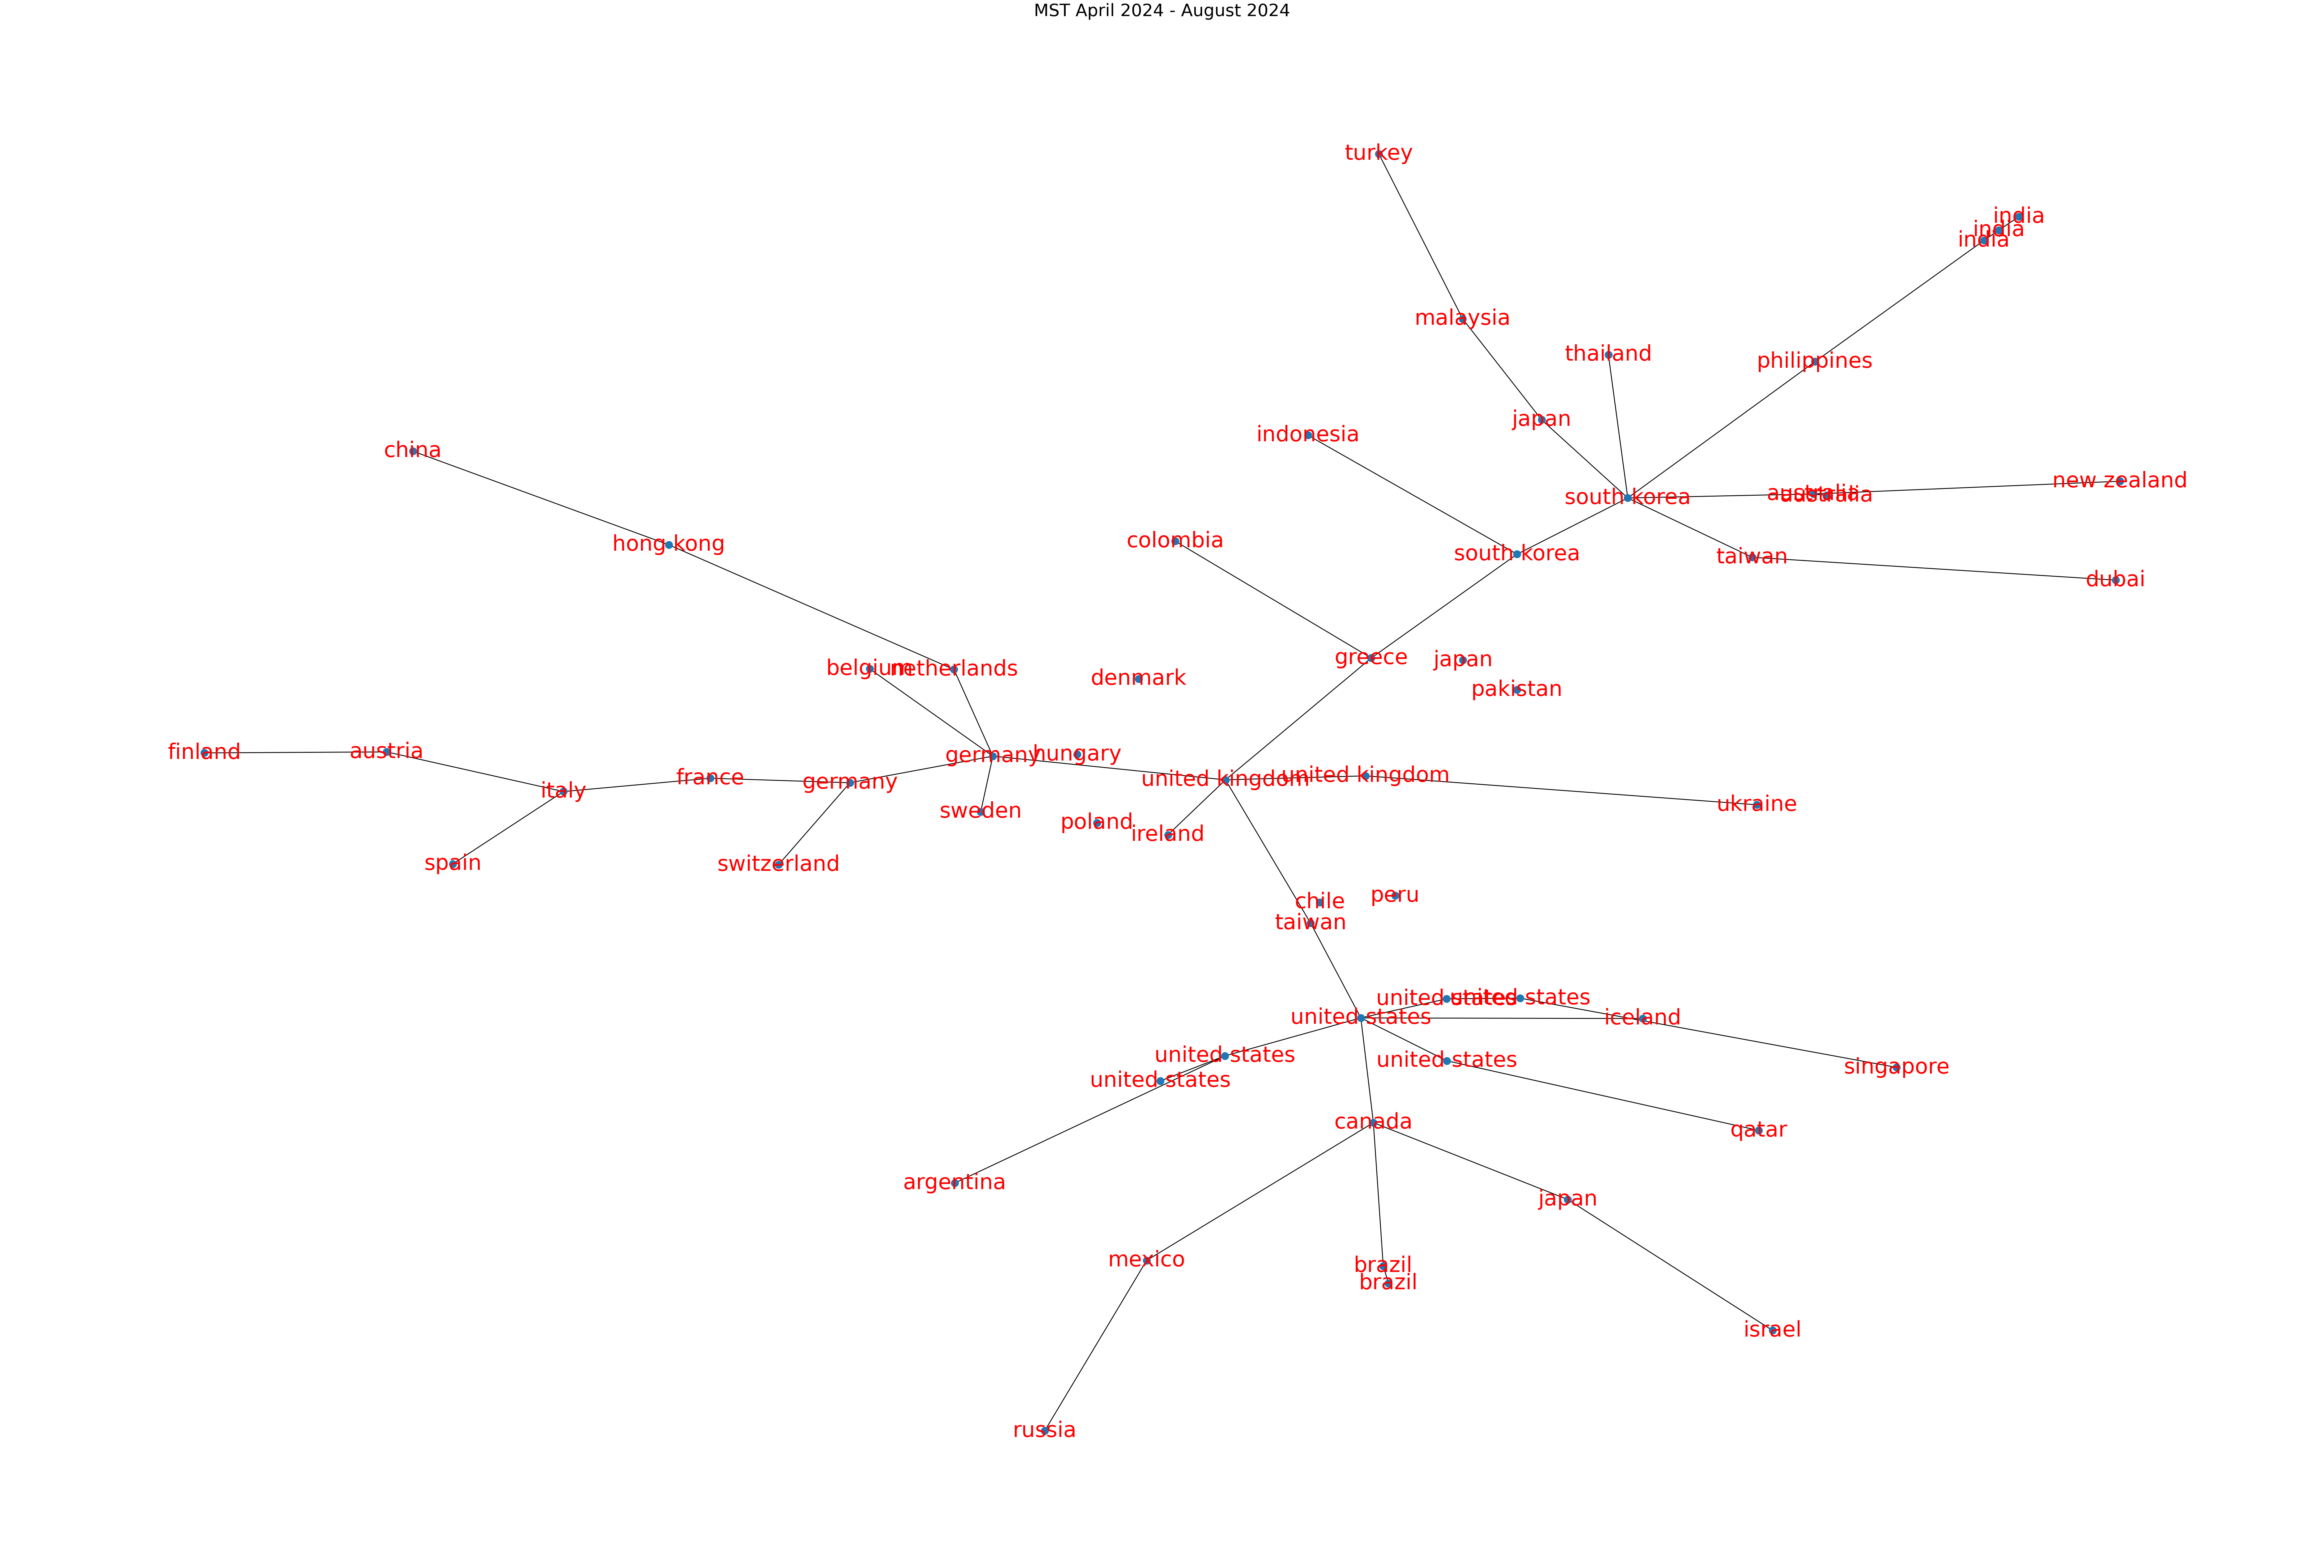

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2024, 4, 1)
end_date = datetime.datetime(2024, 8, 15)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('MST April 2024 - August 2024', fontsize=40)
plt.show()

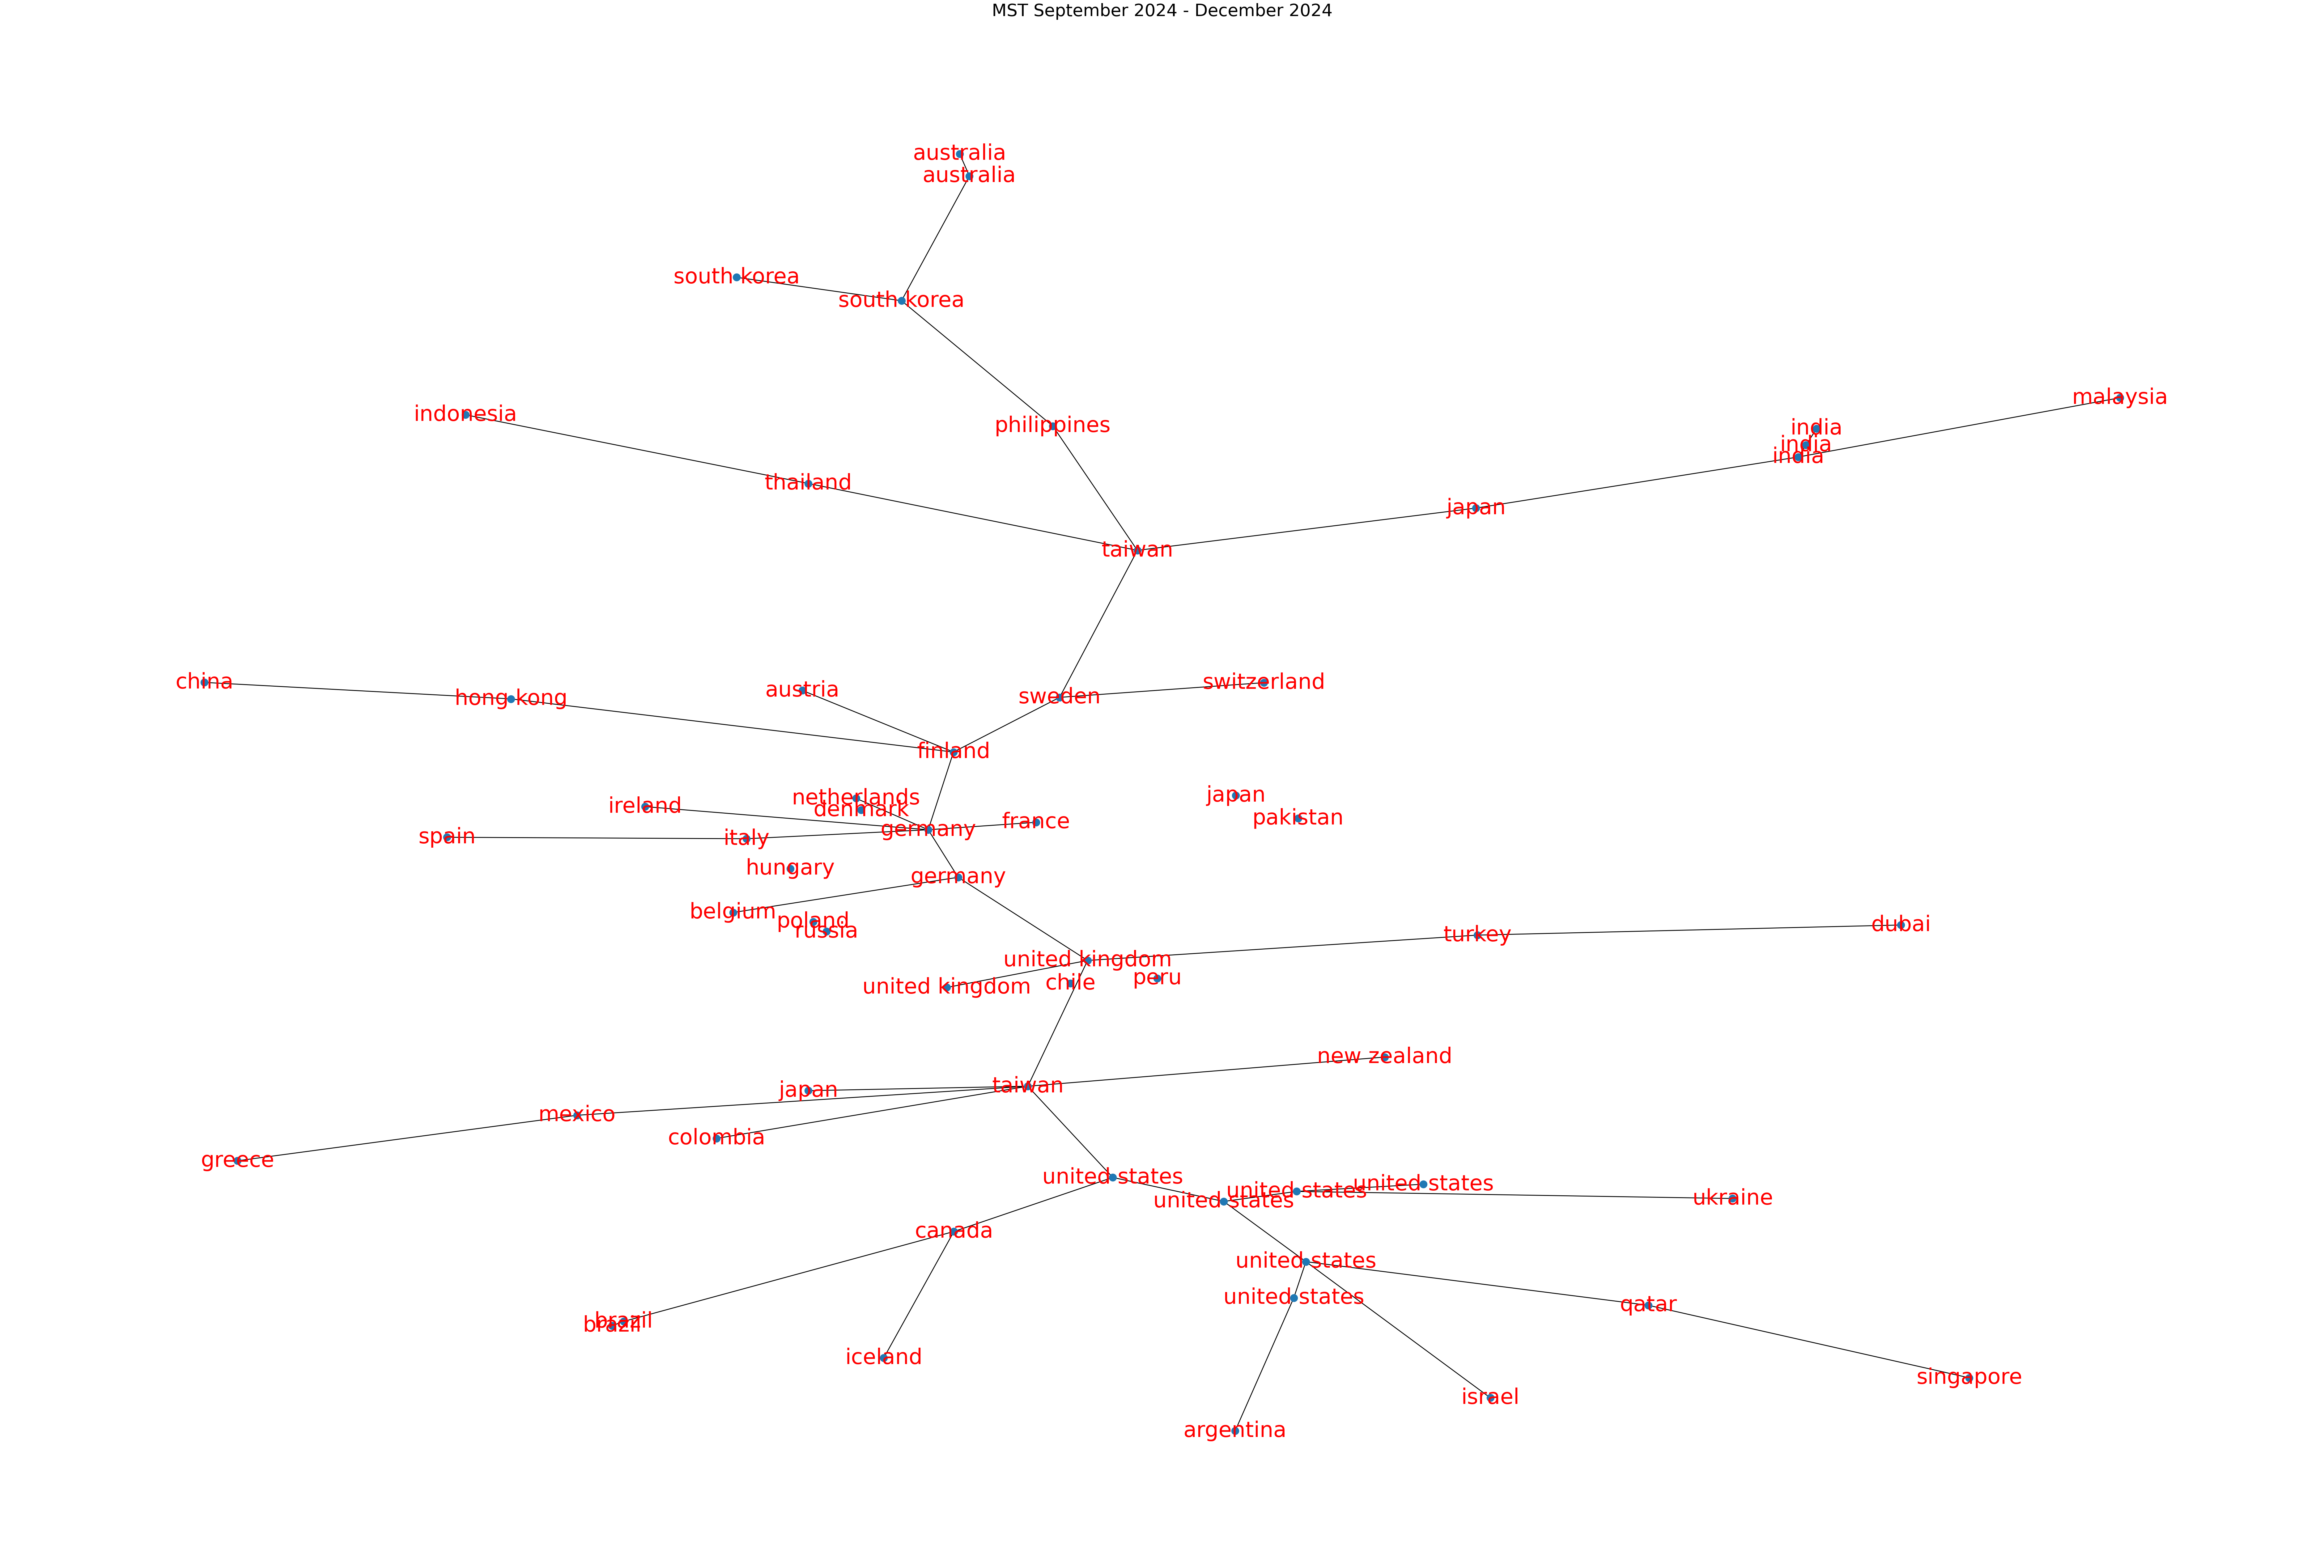

In [ ]:
f = plt.figure(figsize=(75, 50))
start_date = datetime.datetime(2024, 9, 15)
end_date = datetime.datetime(2025, 1, 1)
mask = (data3.index >= start_date) & (data3.index < end_date)
period_data = data3.loc[mask]
corr_period = period_data.corr()
corr_period_matrix = corr_period
corr_period_matrix = corr_period_matrix.to_numpy()
adjacency_matrix = np.sqrt(2*(1-corr_period_matrix))

G = nx.from_numpy_array(adjacency_matrix)
T = nx.minimum_spanning_tree(G,ignore_nan=True)
nx.draw_kamada_kawai(T, with_labels=True, labels=countries_dict, font_color='r', edge_color='black', width=2, font_size=50)
plt.title('MST September 2024 - December 2024', fontsize=40)
plt.show()